# Chronological model validation and policy evaluation
Candidates and calibration methods are selected by forward validation Brier score with a ranking guard. July-August revalidation is retrospective; failed gates are retained.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
def report(name): return pd.read_csv(ROOT / 'reports' / (name + '.csv'))
def metadata(name): return json.loads((ROOT / 'reports' / (name + '.json')).read_text())
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
metadata('model_evaluation')

{'selected_model': 'logistic__raw',
 'model_version': 'purchase-v3-frozen-20180701',
 'model_available_at': '2018-07-01 00:00:00',
 'feature_schema_sha256': 'bb535ee782b34072f615ad7974413b6d32c8e18375abdc31a733c1b1920b9732',
 'splits': {'train': {'n': 43609,
   'purchase_min': '2016-09-15 12:16:38',
   'purchase_max': '2017-12-31 23:29:31',
   'max_label_known_at': '2018-01-31 23:45:08'},
  'method_fit': {'n': 6231,
   'purchase_min': '2018-02-01 00:24:55',
   'purchase_max': '2018-02-28 23:57:55',
   'max_label_known_at': '2018-03-31 13:51:44'},
  'validation': {'n': 6715,
   'purchase_min': '2018-04-01 00:11:32',
   'purchase_max': '2018-04-30 23:47:26',
   'max_label_known_at': '2018-05-31 00:09:39'},
  'calibration': {'n': 6726,
   'purchase_min': '2018-05-01 00:02:11',
   'purchase_max': '2018-05-31 23:51:24',
   'max_label_known_at': '2018-06-30 17:35:34'},
  'test': {'n': 12507,
   'purchase_min': '2018-07-01 00:25:07',
   'purchase_max': '2018-08-29 15:00:37',
   'max_label_kno

In [3]:
report('model_comparison')

,model,split,n,late_rate,roc_auc,average_precision,brier,log_loss,precision_at_50_daily,recall_at_50_daily,selected,late_captured
0,constant__raw,validation,6715,0.034252,0.500000,0.034252,0.033489,0.153782,0.029333,0.191304,1500,44
1,logistic__raw,validation,6715,0.034252,0.773222,0.119384,0.031753,0.134734,0.093333,0.608696,1500,140
2,logistic__sigmoid,validation,6715,0.034252,0.773222,0.119384,0.043962,0.196631,0.093333,0.608696,1500,140
3,logistic__isotonic,validation,6715,0.034252,0.770682,0.101091,0.044527,0.196442,0.090667,0.591304,1500,136
4,xgboost_depth3__raw,validation,6715,0.034252,0.743920,0.130309,0.033094,0.149624,0.078000,0.508696,1500,117
5,xgboost_depth3__sigmoid,validation,6715,0.034252,0.743920,0.130309,0.042554,0.198875,0.078000,0.508696,1500,117
6,xgboost_depth3__isotonic,validation,6715,0.034252,0.722803,0.109224,0.046696,0.248515,0.070000,0.456522,1500,105
7,xgboost_depth5__raw,validation,6715,0.034252,0.747840,0.119489,0.034111,0.154677,0.080000,0.521739,1500,120
8,xgboost_depth5__sigmoid,validation,6715,0.034252,0.747840,0.119489,0.044447,0.206542,0.080000,0.521739,1500,120
9,xgboost_depth5__isotonic,validation,6715,0.034252,0.732014,0.088275,0.045806,0.212751,0.076000,0.495652,1500,114


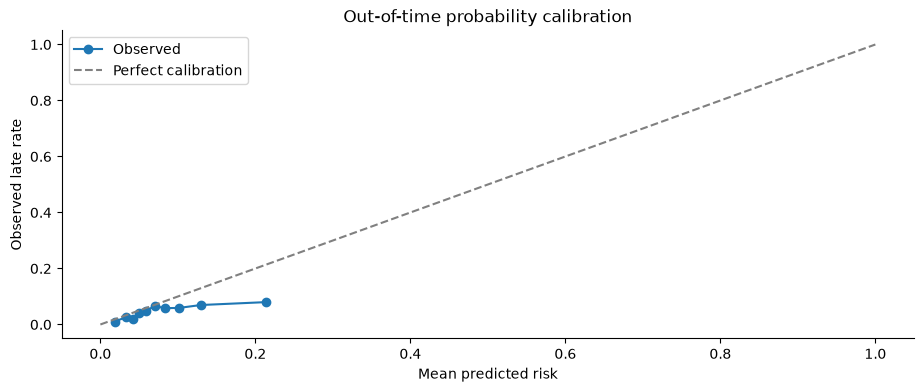

In [4]:
cal=report('calibration')
plt.plot(cal.predicted,cal.observed,'o-',label='Observed');plt.plot([0,1],[0,1],'--',color='gray',label='Perfect calibration');plt.xlabel('Mean predicted risk');plt.ylabel('Observed late rate');plt.legend();plt.title('Out-of-time probability calibration');plt.show()

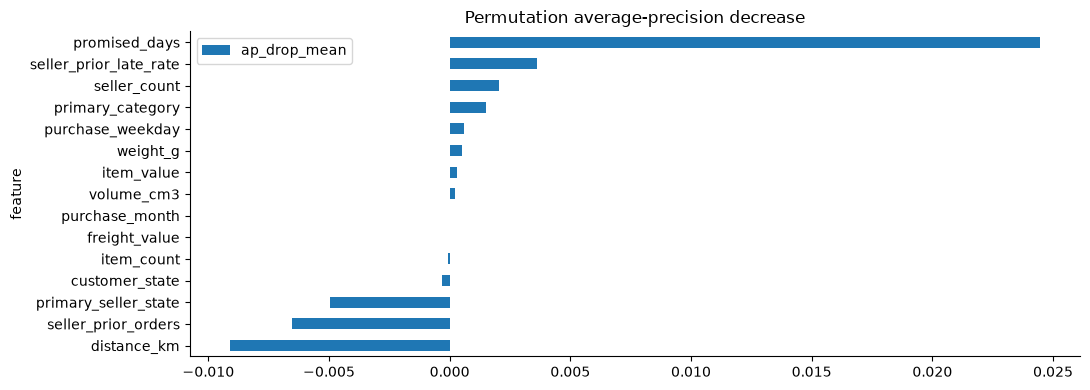

In [5]:
importance=report('feature_importance').sort_values('ap_drop_mean')
importance.plot.barh(x='feature',y='ap_drop_mean',title='Permutation average-precision decrease');plt.tight_layout();plt.show()

In [6]:
report('model_segments').query("field=='customer_state'").sort_values('average_precision',ascending=False)

,field,segment,n,late_rate,roc_auc,average_precision,brier,log_loss,precision_at_50_daily,recall_at_50_daily,selected,late_captured
12,customer_state,SP,5876,0.065521,0.671441,0.114519,0.059936,0.230572,0.070592,0.532468,2904,205
4,customer_state,GO,229,0.034934,0.744910,0.113874,0.035263,0.160435,0.034934,1.000000,229,8
9,customer_state,RJ,1419,0.041579,0.731667,0.094942,0.048440,0.205737,0.041579,1.000000,1419,59
3,customer_state,ES,225,0.040000,0.481481,0.091853,0.046449,0.207034,0.040000,1.000000,225,9
7,customer_state,PE,219,0.054795,0.595411,0.080468,0.060657,0.248834,0.054795,1.000000,219,12
11,customer_state,SC,396,0.025253,0.481865,0.078455,0.034508,0.173458,0.025253,1.000000,396,10
6,customer_state,PA,100,0.030000,0.604811,0.068388,0.039296,0.182329,0.030000,1.000000,100,3
2,customer_state,DF,308,0.038961,0.554899,0.058678,0.038974,0.173830,0.038961,1.000000,308,12
10,customer_state,RS,601,0.023295,0.576904,0.053793,0.026679,0.137055,0.023295,1.000000,601,14
0,customer_state,BA,404,0.039604,0.612436,0.053618,0.050835,0.220072,0.039604,1.000000,404,16


In [7]:
report('adjusted_logistic_coefficients').assign(absolute=lambda d:d.coefficient.abs()).sort_values('absolute',ascending=False).head(20)

,encoded_feature,coefficient,absolute
13,category__customer_state_AL,1.069218,1.069218
22,category__customer_state_MG,-0.790519,0.790519
23,category__customer_state_MS,-0.735743,0.735743
36,category__customer_state_SE,0.703129,0.703129
32,category__customer_state_RO,-0.628686,0.628686
37,category__customer_state_SP,-0.608842,0.608842
29,category__customer_state_PR,-0.593425,0.593425
113,category__primary_category_market_place,-0.583344,0.583344
63,category__primary_category_audio,0.563908,0.563908
30,category__customer_state_RJ,0.562610,0.562610


In [8]:
report('strategy_comparison')

,strategy,selected,labeled,late_captured,predicted_late,scenario_cost,scenario_net_benefit,observed_precision
0,Highest risk,2963,2890,163,459.208642,14815.0,2984.201931,0.056401
1,Optimized scenario,1647,1602,130,316.774110,8235.0,5274.808425,0.081149
2,Prior seller risk,2963,2894,133,319.670109,14815.0,-2850.843233,0.045957
3,Random seed 0,2963,2890,102,228.100063,14815.0,-6205.365675,0.035294
4,Random seed 1,2963,2882,118,232.357296,14815.0,-6080.688389,0.040944
5,Random seed 2,2963,2891,117,234.654439,14815.0,-6096.152258,0.040470
6,Random seed 3,2963,2889,106,230.478011,14815.0,-6140.793421,0.036691
7,Random seed 4,2963,2892,130,231.546486,14815.0,-6137.739409,0.044952
8,Random seed 5,2963,2886,115,230.799415,14815.0,-5842.370217,0.039848
9,Random seed 6,2963,2884,139,228.940635,14815.0,-6400.440757,0.048197


In [9]:
report('scenario_sensitivity')

,scenario_id,scenario_name,capacity,budget,cost,effectiveness,impact,value_fraction,region_cap,interpretation,selected,assumed_cost,hypothetical_net_benefit
0,71111bc56997,Assumed effectiveness 10%,50,500.0,5.0,0.1,150.0,0.25,50,Hypothetical BRL amounts; no measured interven...,282,1410.0,769.296551
1,8736db5e2293,Assumed effectiveness 20%,50,500.0,5.0,0.2,150.0,0.25,50,Hypothetical BRL amounts; no measured interven...,1647,8235.0,5274.808425
2,aa4d819c7074,Assumed effectiveness 30%,50,500.0,5.0,0.3,150.0,0.25,50,Hypothetical BRL amounts; no measured interven...,2518,12590.0,13166.577307


Local reference changes and global permutation importance explain associations, not intervention effects. Delivered-only labels, attribute-version assumptions, right censoring and temporal calibration shifts limit operational claims.